In [3]:
import os
from pathlib import Path
from collections import Counter

base = Path("/kaggle/input")

for p in sorted(base.iterdir()):
    print("montato:", p)

tot = 0
exts = Counter()
for dirpath, dirnames, filenames in os.walk(base):
    if filenames:
        rel = os.path.relpath(dirpath, base)
        print(f"{rel} -> {len(filenames)} file")
        tot += len(filenames)
        exts.update(Path(f).suffix.lower() for f in filenames)

print("File totali:", tot)
print(exts)

montato: /kaggle/input/datasets
datasets/robiulhasan21/cervical-cancer-image-largest-dataset/Image/ASCUS -> 1100 file
datasets/robiulhasan21/cervical-cancer-image-largest-dataset/Image/HSIL -> 1550 file
datasets/robiulhasan21/cervical-cancer-image-largest-dataset/Image/LSIL -> 1454 file
datasets/robiulhasan21/cervical-cancer-image-largest-dataset/Image/NILM -> 2101 file
datasets/robiulhasan21/cervical-cancer-image-largest-dataset/Image/SCC -> 1136 file
File totali: 7341
Counter({'.jpg': 6016, '.png': 941, '.jpeg': 384})


In [4]:
import os, hashlib
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

ROOT = Path("/kaggle/input/datasets/robiulhasan21/cervical-cancer-image-largest-dataset/Image")
CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]
exts = {".jpg", ".jpeg", ".png"}

rows = [{"path": str(p), "label": c}
        for c in CLASSES for p in (ROOT / c).iterdir()
        if p.suffix.lower() in exts]
df = pd.DataFrame(rows)
df["y"] = df["label"].map({c: i for i, c in enumerate(CLASSES)})

def md5(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["size"] = df["path"].map(os.path.getsize)
mask = df.duplicated("size", keep=False)
df["md5"] = df["path"]
with ThreadPoolExecutor(8) as ex:
    hashes = list(tqdm(ex.map(md5, df.loc[mask, "path"]), total=mask.sum()))
df.loc[mask, "md5"] = hashes

conf = df.groupby("md5")["label"].agg(lambda s: tuple(sorted(set(s))))
conf = conf[conf.map(len) > 1]
print(conf.value_counts())

df = df[~df["md5"].isin(conf.index)]
df = df.drop_duplicates("md5").reset_index(drop=True)
print(df["label"].value_counts(), len(df))

train_val, test = train_test_split(df, test_size=0.20, stratify=df["y"], random_state=42)
train, val = train_test_split(train_val, test_size=0.125, stratify=train_val["y"], random_state=42)
print(len(train), len(val), len(test))

for name, d in [("train", train), ("val", val), ("test", test)]:
    d.to_csv(f"/kaggle/working/{name}.csv", index=False)

  0%|          | 0/1007 [00:00<?, ?it/s]

label
(ASCUS, NILM)                37
(HSIL, LSIL)                 26
(ASCUS, LSIL)                16
(HSIL, NILM)                  9
(ASCUS, HSIL)                 6
(ASCUS, LSIL, NILM)           4
(ASCUS, HSIL, NILM)           4
(ASCUS, HSIL, LSIL)           4
(ASCUS, HSIL, LSIL, NILM)     2
(LSIL, NILM)                  2
(HSIL, SCC)                   1
(LSIL, SCC)                   1
Name: count, dtype: int64
label
NILM     1790
HSIL     1409
LSIL     1345
SCC      1113
ASCUS     963
Name: count, dtype: int64 6620
4634 662 1324


In [5]:
import pandas as pd
from pathlib import Path
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

SIZE = 256
OUT = Path("/kaggle/working/img256")
splits = {n: pd.read_csv(f"/kaggle/working/{n}.csv") for n in ["train", "val", "test"]}

def resize_one(row):
    src = Path(row["path"])
    dst = OUT / row["label"] / f"{src.stem}_{src.suffix[1:].lower()}.jpg"
    dst.parent.mkdir(parents=True, exist_ok=True)
    if not dst.exists():
        with Image.open(src) as im:
            im.draft("RGB", (SIZE * 2, SIZE * 2))
            im = im.convert("RGB").resize((SIZE, SIZE), Image.LANCZOS)
            im.save(dst, "JPEG", quality=95)
    return str(dst)

for name, d in splits.items():
    rows = d.to_dict("records")
    with ThreadPoolExecutor(4) as ex:
        d["path_small"] = list(tqdm(ex.map(resize_one, rows), total=len(rows), desc=name))
    d.to_csv(f"/kaggle/working/{name}.csv", index=False)

train:   0%|          | 0/4634 [00:00<?, ?it/s]

val:   0%|          | 0/662 [00:00<?, ?it/s]

test:   0%|          | 0/1324 [00:00<?, ?it/s]

In [6]:
!pip install -q imagehash

In [7]:
import numpy as np, imagehash

df = pd.concat([d.assign(split=n) for n, d in splits.items()], ignore_index=True)

def phash_bits(p):
    with Image.open(p) as im:
        return imagehash.phash(im).hash.flatten().astype(np.float32)

with ThreadPoolExecutor(4) as ex:
    B = np.stack(list(tqdm(ex.map(phash_bits, df["path_small"]), total=len(df))))

D = B.shape[1] - (B @ B.T + (1 - B) @ (1 - B).T)
np.fill_diagonal(D, 99)

T = 4
i, j = np.where(np.triu(D <= T, 1))
pairs = pd.DataFrame({
    "split_i": df["split"].values[i], "split_j": df["split"].values[j],
    "label_i": df["label"].values[i], "label_j": df["label"].values[j],
})
print("Coppie quasi-duplicate:", len(pairs))
print("Tra split diversi (leakage):", (pairs.split_i != pairs.split_j).sum())
print("Con etichette diverse:", (pairs.label_i != pairs.label_j).sum())

  0%|          | 0/6620 [00:00<?, ?it/s]

Coppie quasi-duplicate: 360
Tra split diversi (leakage): 147
Con etichette diverse: 6


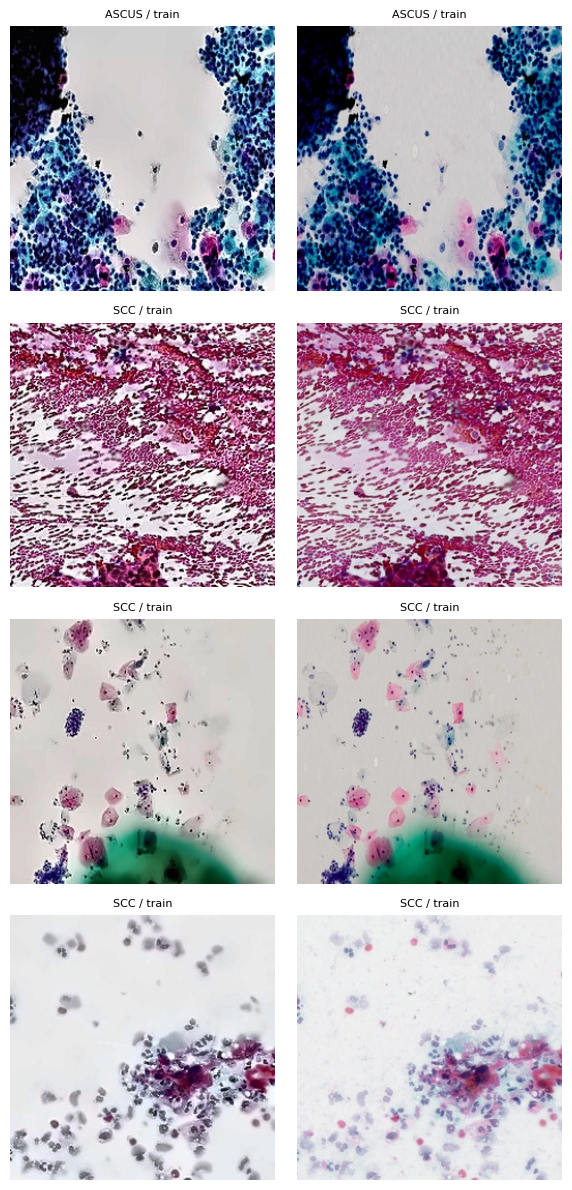

In [8]:
import matplotlib.pyplot as plt

sel = np.random.RandomState(0).choice(len(i), 4, replace=False)
fig, axes = plt.subplots(4, 2, figsize=(6, 12))
for r, k in enumerate(sel):
    for c, ix in enumerate((i[k], j[k])):
        axes[r, c].imshow(Image.open(df["path_small"][ix]))
        axes[r, c].set_title(f'{df["label"][ix]} / {df["split"][ix]}', fontsize=8)
        axes[r, c].axis("off")
plt.tight_layout(); plt.show()

In [9]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold

n = len(df)
adj = coo_matrix((np.ones(len(i)), (i, j)), shape=(n, n))
n_groups, group = connected_components(adj, directed=False)
df["group"] = group

bad = df.groupby("group")["label"].nunique()
bad = bad[bad > 1].index
df = df[~df["group"].isin(bad)].reset_index(drop=True)
print("Gruppi in conflitto rimossi:", len(bad), "| immagini rimaste:", len(df))

sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)
df["fold"] = -1
for f, (_, idx) in enumerate(sgkf.split(df, df["y"], df["group"])):
    df.loc[idx, "fold"] = f
df["split"] = np.where(df["fold"] < 2, "test", np.where(df["fold"] == 2, "val", "train"))

print(df["split"].value_counts(normalize=True).round(3))
print(df.groupby(["split", "label"]).size().unstack())
print("Gruppi presenti in più split (deve essere 0):",
      (df.groupby("group")["split"].nunique() > 1).sum())

for name in ["train", "val", "test"]:
    df[df["split"] == name].drop(columns=["fold"]).to_csv(f"/kaggle/working/{name}.csv", index=False)

Gruppi in conflitto rimossi: 6 | immagini rimaste: 6608
split
train    0.702
test     0.199
val      0.099
Name: proportion, dtype: float64
label  ASCUS  HSIL  LSIL  NILM  SCC
split                              
test     185   276   268   365  220
train    682   987   945  1240  784
val       94   142   129   183  108
Gruppi presenti in più split (deve essere 0): 0


In [10]:
import torch, numpy as np, pandas as pd
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])

class CervicalDataset(Dataset):
    def __init__(self, csv_file, transform):
        df = pd.read_csv(csv_file)
        self.paths = df["path_small"].tolist()
        self.labels = df["y"].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        image = Image.open(self.paths[i]).convert("RGB")
        return self.transform(image), self.labels[i]

train_ds = CervicalDataset("/kaggle/working/train.csv", train_tf)
val_ds = CervicalDataset("/kaggle/working/val.csv", eval_tf)
test_ds = CervicalDataset("/kaggle/working/test.csv", eval_tf)

train_dl = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=32, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=32, num_workers=2)

counts = np.bincount(train_ds.labels, minlength=5)
class_weights = torch.tensor(len(train_ds) / (5 * counts), dtype=torch.float32)

x, y = next(iter(train_dl))
print(x.shape, counts, class_weights)

torch.Size([32, 3, 224, 224]) [ 682  987  945 1240  784] tensor([1.3601, 0.9398, 0.9816, 0.7481, 1.1832])


In [24]:
import torch.nn as nn, torchvision
from sklearn.metrics import f1_score

device = "cuda"
CLASSES = ["ASCUS", "HSIL", "LSIL", "NILM", "SCC"]
model = torchvision.models.resnet50(weights="IMAGENET1K_V2")
model.fc = nn.Linear(model.fc.in_features, 5)
model = model.to(device)
loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))

def train_one_epoch(optimizer):
    model.train()
    total_loss = 0
    for x, y in train_dl:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(x)
    return total_loss / len(train_ds)

def evaluate(dl):
    model.eval()
    all_pred, all_true = [], []
    total_loss = 0
    with torch.no_grad():
        for x, y in dl:
            out = model(x.to(device))
            total_loss += loss_fn(out, y.to(device)).item() * len(x)
            all_pred += out.argmax(1).cpu().tolist()
            all_true += y.tolist()
    acc = float(np.mean(np.array(all_pred) == np.array(all_true)))
    f1 = f1_score(all_true, all_pred, average="macro")
    return total_loss / len(dl.dataset), acc, f1, all_true, all_pred

train_losses, val_losses = [], []
best_f1 = 0

for p in model.parameters():
    p.requires_grad = False
for p in model.fc.parameters():
    p.requires_grad = True
opt = torch.optim.AdamW(model.fc.parameters(), lr=1e-3, weight_decay=1e-4)
for epoch in range(3):
    train_loss = train_one_epoch(opt)
    val_loss, acc, f1, _, _ = evaluate(val_dl)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print("fase 1", epoch, "val acc", round(acc, 3), "f1", round(f1, 3))

for p in model.parameters():
    p.requires_grad = True
opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
for epoch in range(10):
    train_loss = train_one_epoch(opt)
    val_loss, acc, f1, _, _ = evaluate(val_dl)
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    print("fase 2", epoch, "val acc", round(acc, 3), "f1", round(f1, 3))
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), "/kaggle/working/resnet50.pt")

fase 1 0 val acc 0.62 f1 0.575
fase 1 1 val acc 0.631 f1 0.589
fase 1 2 val acc 0.657 f1 0.626
fase 2 0 val acc 0.745 f1 0.733
fase 2 1 val acc 0.787 f1 0.772
fase 2 2 val acc 0.8 f1 0.789
fase 2 3 val acc 0.79 f1 0.781
fase 2 4 val acc 0.796 f1 0.781
fase 2 5 val acc 0.777 f1 0.767
fase 2 6 val acc 0.805 f1 0.795
fase 2 7 val acc 0.8 f1 0.79
fase 2 8 val acc 0.797 f1 0.789
fase 2 9 val acc 0.809 f1 0.802


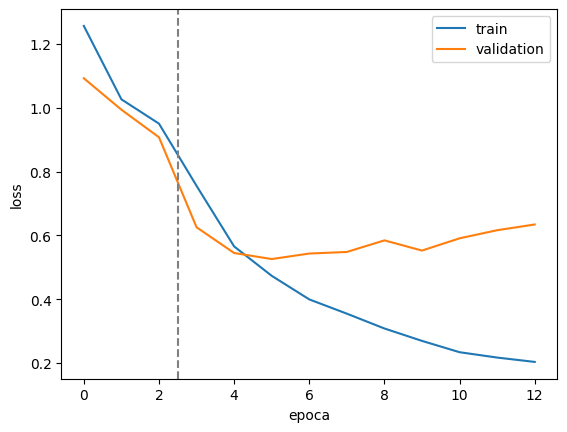

In [25]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label="train")
plt.plot(val_losses, label="validation")
plt.axvline(2.5, linestyle="--", color="gray")
plt.xlabel("epoca")
plt.ylabel("loss")
plt.legend()
plt.show()

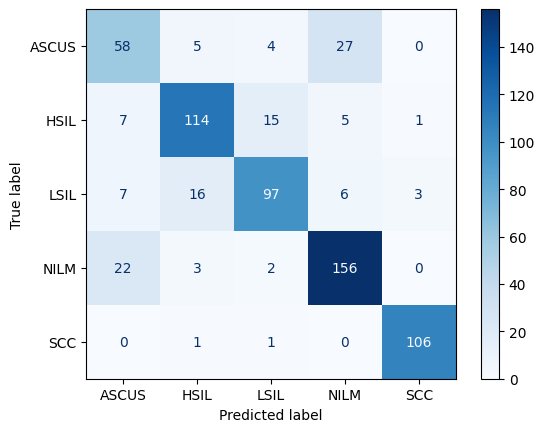

              precision    recall  f1-score   support

       ASCUS      0.617     0.617     0.617        94
        HSIL      0.820     0.803     0.811       142
        LSIL      0.815     0.752     0.782       129
        NILM      0.804     0.852     0.828       183
         SCC      0.964     0.981     0.972       108

    accuracy                          0.809       656
   macro avg      0.804     0.801     0.802       656
weighted avg      0.809     0.809     0.809       656



In [26]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

model.load_state_dict(torch.load("/kaggle/working/resnet50.pt"))
_, acc, f1, y_true, y_pred = evaluate(val_dl)

ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=CLASSES, cmap="Blues")
plt.show()
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=3))

In [27]:
results = []
for lr in [3e-5, 1e-4, 3e-4]:
    for wd in [1e-4, 1e-2]:
        model = torchvision.models.resnet50(weights="IMAGENET1K_V2")
        model.fc = nn.Linear(model.fc.in_features, 5)
        model = model.to(device)
        loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device), label_smoothing=0.1)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)

        best = 0
        for epoch in range(8):
            train_one_epoch(opt)
            f1 = evaluate(val_dl)[2]
            best = max(best, f1)
        results.append((lr, wd, round(best, 3)))
        print(lr, wd, round(best, 3))

#non vale la pena aumenta di troppo poco per il costo computazionale

KeyboardInterrupt: 

In [28]:
model.load_state_dict(torch.load("/kaggle/working/resnet50.pt"))
model.fc = nn.Identity()
model.eval()

def extract(dl):
    feats, labels = [], []
    with torch.no_grad():
        for x, y in dl:
            feats.append(model(x.to(device)).cpu())
            labels.append(y)
    return torch.cat(feats), torch.cat(labels)

train_plain_dl = DataLoader(CervicalDataset("/kaggle/working/train.csv", eval_tf),
                            batch_size=32, num_workers=2)
Xtr, ytr = extract(train_plain_dl)
Xva, yva = extract(val_dl)
print(Xtr.shape, Xva.shape)

torch.Size([4638, 2048]) torch.Size([656, 2048])


In [29]:
import torch.nn.functional as F

PRIOR_STD = 0.05

class BayesLinear(nn.Module):
    def __init__(self, n_in, n_out):
        super().__init__()
        self.w_mu = nn.Parameter(torch.zeros(n_out, n_in))
        self.w_rho = nn.Parameter(torch.full((n_out, n_in), -5.0))
        self.b_mu = nn.Parameter(torch.zeros(n_out))
        self.b_rho = nn.Parameter(torch.full((n_out,), -5.0))

    def forward(self, x):
        w_sigma = F.softplus(self.w_rho)
        b_sigma = F.softplus(self.b_rho)
        w = self.w_mu + w_sigma * torch.randn_like(w_sigma)
        b = self.b_mu + b_sigma * torch.randn_like(b_sigma)
        return x @ w.T + b

    def kl(self):
        total = 0
        for mu, rho in [(self.w_mu, self.w_rho), (self.b_mu, self.b_rho)]:
            sigma = F.softplus(rho)
            total += (torch.log(PRIOR_STD / sigma) + (sigma**2 + mu**2) / (2 * PRIOR_STD**2) - 0.5).sum()
        return total

layer = BayesLinear(2048, 5).to(device)
Xtr_d, ytr_d = Xtr.to(device), ytr.to(device)
opt = torch.optim.Adam(layer.parameters(), lr=5e-3)
kl_weight = 1 / len(Xtr)

for epoch in range(100):
    order = torch.randperm(len(Xtr_d), device=device)
    for i in range(0, len(order), 256):
        idx = order[i:i + 256]
        loss = F.cross_entropy(layer(Xtr_d[idx]), ytr_d[idx]) + kl_weight * layer.kl()
        opt.zero_grad()
        loss.backward()
        opt.step()
    if epoch % 20 == 0:
        print("epoca", epoch, "loss", round(loss.item(), 3))

epoca 0 loss 3.646
epoca 20 loss 0.532
epoca 40 loss 0.705
epoca 60 loss 0.463
epoca 80 loss 0.626


In [30]:
from sklearn.metrics import f1_score

with torch.no_grad():
    probs = torch.stack([F.softmax(layer(Xva.to(device)), dim=1) for _ in range(50)])

mean_p = probs.mean(0)
pred = mean_p.argmax(1).cpu()
print("val acc", (pred == yva).float().mean().item(), "f1", f1_score(yva, pred, average="macro"))

entropy = -(mean_p * torch.log(mean_p + 1e-9)).sum(1)
aleatoric = -(probs * torch.log(probs + 1e-9)).sum(2).mean(0)
epistemic = entropy - aleatoric

wrong = pred != yva
print("incertezza media, corrette:", entropy.cpu()[~wrong].mean().item(),
      "| sbagliate:", entropy.cpu()[wrong].mean().item())
print("sigma media dei pesi:", F.softplus(layer.w_rho).mean().item())

val acc 0.8079268336296082 f1 0.7976658176038367
incertezza media, corrette: 0.4250176250934601 | sbagliate: 0.9807240962982178
sigma media dei pesi: 0.04824284836649895


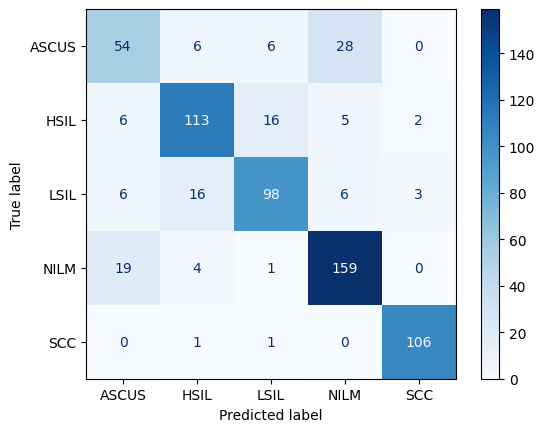

              precision    recall  f1-score   support

       ASCUS      0.635     0.574     0.603        94
        HSIL      0.807     0.796     0.801       142
        LSIL      0.803     0.760     0.781       129
        NILM      0.803     0.869     0.835       183
         SCC      0.955     0.981     0.968       108

    accuracy                          0.808       656
   macro avg      0.801     0.796     0.798       656
weighted avg      0.805     0.808     0.806       656



In [31]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

ConfusionMatrixDisplay.from_predictions(yva, pred, display_labels=CLASSES, cmap="Blues")
plt.show()
print(classification_report(yva, pred, target_names=CLASSES, digits=3))

preds = probs.argmax(2).cpu()
recalls = np.array([[(preds[s][yva == c] == c).float().mean().item() for c in range(5)]
                    for s in range(50)])
low, mid, high = np.percentile(recalls, [2.5, 50, 97.5], axis=0)

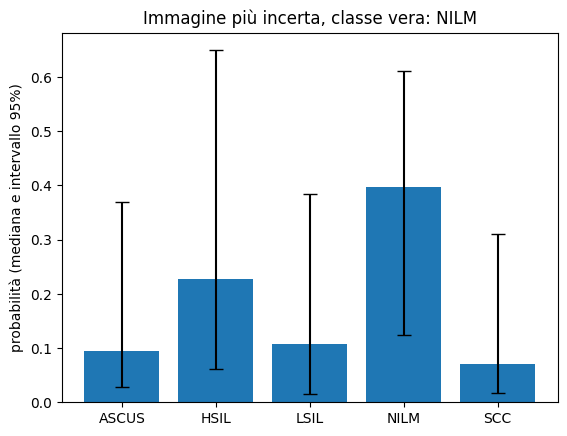

In [32]:
i = int(entropy.argmax())
p = probs[:, i, :].cpu().numpy()
low, mid, high = np.percentile(p, [2.5, 50, 97.5], axis=0)

plt.bar(CLASSES, mid, yerr=[mid - low, high - mid], capsize=5)
plt.ylabel("probabilità (mediana e intervallo 95%)")
plt.title(f"Immagine più incerta, classe vera: {CLASSES[int(yva[i])]}")
plt.show()

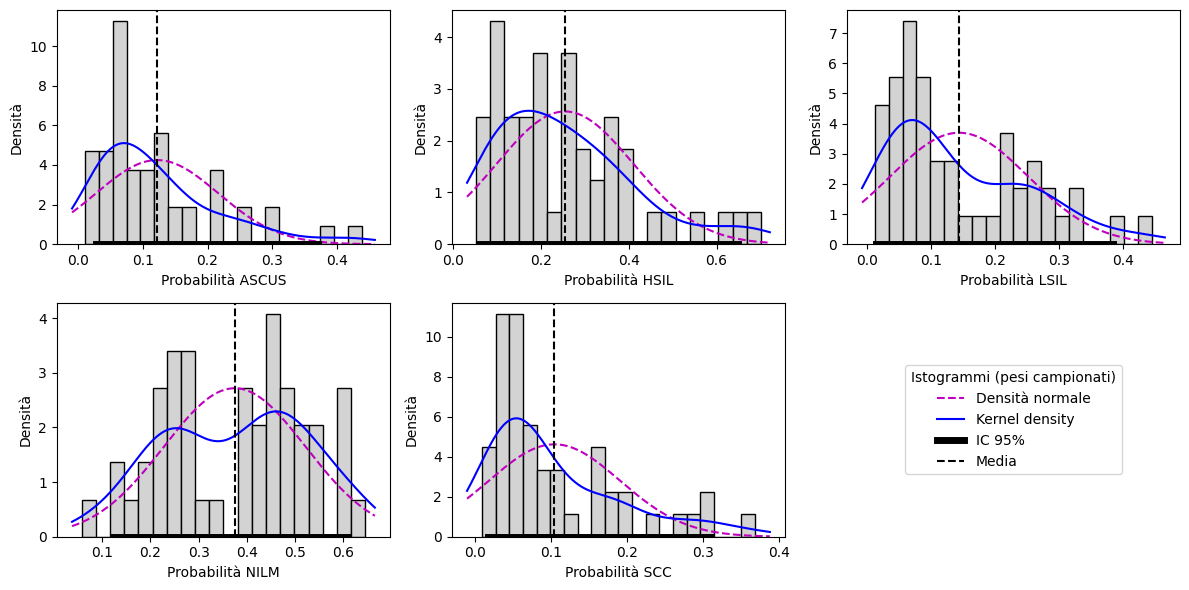

In [33]:
from scipy.stats import norm, gaussian_kde

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
axes = axes.flatten()

for c in range(5):
    ax = axes[c]
    s = p[:, c]
    dev = max(s.std(), 1e-4)
    xs = np.linspace(s.min() - 0.02, s.max() + 0.02, 300)

    ax.hist(s, bins=20, density=True, color="lightgray", edgecolor="black")
    ax.plot(xs, norm.pdf(xs, s.mean(), dev), "m--", label="Densità normale")
    ax.plot(xs, gaussian_kde(s)(xs), "b-", label="Kernel density")
    low, high = np.percentile(s, [2.5, 97.5])
    ax.plot([low, high], [0, 0], "k-", linewidth=5, label="IC 95%")
    ax.axvline(s.mean(), color="k", linestyle="--", label="Media")
    ax.set_xlabel(f"Probabilità {CLASSES[c]}")
    ax.set_ylabel("Densità")

handles, labels = axes[0].get_legend_handles_labels()
axes[5].axis("off")
axes[5].legend(handles, labels, loc="center", title="Istogrammi (pesi campionati)")

plt.tight_layout()
plt.show()

In [37]:
from sklearn.metrics import f1_score

head = nn.Sequential(nn.Dropout(0.5), nn.Linear(2048, 5)).to(device)
opt = torch.optim.Adam(head.parameters(), lr=1e-3, weight_decay=1e-4)

head.train()
for epoch in range(100):
    order = torch.randperm(len(Xtr_d), device=device)
    for i in range(0, len(order), 256):
        idx = order[i:i + 256]
        loss = F.cross_entropy(head(Xtr_d[idx]), ytr_d[idx])
        opt.zero_grad()
        loss.backward()
        opt.step()

head.train()
with torch.no_grad():
    probs_mc = torch.stack([F.softmax(head(Xva.to(device)), dim=1) for _ in range(50)])
p_mc = probs_mc.mean(0).cpu()

pred = p_mc.argmax(1)
print("val acc", (pred == yva).float().mean().item(), "f1", f1_score(yva, pred, average="macro"))
wrong = pred != yva
ent = entropy_of(p_mc)
print("incertezza media, corrette:", ent[~wrong].mean().item(), "| sbagliate:", ent[wrong].mean().item())

val acc 0.8094512224197388 f1 0.8022317099351055
incertezza media, corrette: 0.12555864453315735 | sbagliate: 0.5644323229789734


In [39]:
M = 3
for seed in range(M):
    torch.manual_seed(seed)
    model = torchvision.models.resnet50(weights="IMAGENET1K_V2")
    model.fc = nn.Linear(2048, 5)
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights.to(device))
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)

    best_f1 = 0
    for epoch in range(8):
        train_one_epoch(opt)
        f1 = evaluate(val_dl)[2]
        print("modello", seed, "epoca", epoch, "f1", round(f1, 3))
        if f1 > best_f1:
            best_f1 = f1
            torch.save(model.state_dict(), f"/kaggle/working/ens_{seed}.pt")

modello 0 epoca 0 f1 0.706
modello 0 epoca 1 f1 0.705
modello 0 epoca 2 f1 0.759
modello 0 epoca 3 f1 0.798
modello 0 epoca 4 f1 0.786
modello 0 epoca 5 f1 0.79
modello 0 epoca 6 f1 0.795
modello 0 epoca 7 f1 0.79
modello 1 epoca 0 f1 0.683
modello 1 epoca 1 f1 0.751
modello 1 epoca 2 f1 0.759
modello 1 epoca 3 f1 0.777
modello 1 epoca 4 f1 0.778
modello 1 epoca 5 f1 0.781
modello 1 epoca 6 f1 0.798
modello 1 epoca 7 f1 0.784
modello 2 epoca 0 f1 0.698
modello 2 epoca 1 f1 0.739
modello 2 epoca 2 f1 0.78
modello 2 epoca 3 f1 0.781
modello 2 epoca 4 f1 0.775
modello 2 epoca 5 f1 0.792
modello 2 epoca 6 f1 0.789
modello 2 epoca 7 f1 0.785


In [40]:
def predict_probs(dl):
    model.eval()
    out = []
    with torch.no_grad():
        for x, y in dl:
            out.append(F.softmax(model(x.to(device)), dim=1).cpu())
    return torch.cat(out)

all_probs = []
for seed in range(M):
    model.load_state_dict(torch.load(f"/kaggle/working/ens_{seed}.pt"))
    all_probs.append(predict_probs(val_dl))
p_ens = torch.stack(all_probs).mean(0)

pred = p_ens.argmax(1)
print("val acc", (pred == yva).float().mean().item(), "f1", f1_score(yva, pred, average="macro"))
wrong = pred != yva
ent = entropy_of(p_ens)
print("incertezza media, corrette:", ent[~wrong].mean().item(), "| sbagliate:", ent[wrong].mean().item())

val acc 0.8216463327407837 f1 0.8102187183406097
incertezza media, corrette: 0.35647669434547424 | sbagliate: 0.9719278812408447


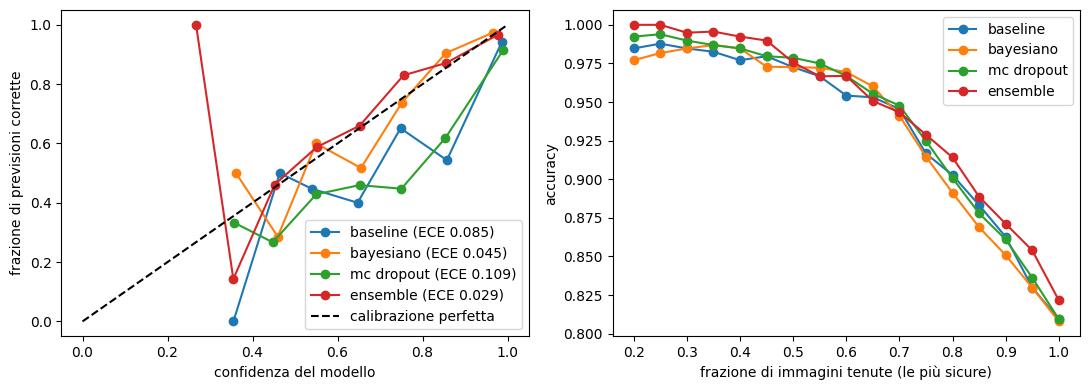

In [41]:
import matplotlib.pyplot as plt

sd = torch.load("/kaggle/working/resnet50.pt")
p_base = F.softmax(Xva @ sd["fc.weight"].cpu().T + sd["fc.bias"].cpu(), dim=1)
p_bayes = mean_p.cpu()
models = [("baseline", p_base), ("bayesiano", p_bayes), ("mc dropout", p_mc), ("ensemble", p_ens)]

def entropy_of(p):
    return -(p * torch.log(p + 1e-9)).sum(1)

def reliability(p, bins=10):
    conf, pred = p.max(1)
    correct = (pred == yva).float()
    xs, ys, ece = [], [], 0
    for i in range(bins):
        m = (conf > i / bins) & (conf <= (i + 1) / bins)
        if m.sum() > 0:
            xs.append(conf[m].mean().item())
            ys.append(correct[m].mean().item())
            ece += m.float().mean().item() * abs(ys[-1] - xs[-1])
    return xs, ys, ece

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for name, p in models:
    xs, ys, ece = reliability(p)
    axes[0].plot(xs, ys, "o-", label=f"{name} (ECE {ece:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", label="calibrazione perfetta")
axes[0].set_xlabel("confidenza del modello")
axes[0].set_ylabel("frazione di previsioni corrette")
axes[0].legend()

for name, p in models:
    order = entropy_of(p).argsort()
    correct = (p.argmax(1) == yva).float()[order]
    kept = [k / 100 for k in range(20, 101, 5)]
    accs = [correct[:int(len(correct) * k)].mean().item() for k in kept]
    axes[1].plot(kept, accs, "o-", label=name)
axes[1].set_xlabel("frazione di immagini tenute (le più sicure)")
axes[1].set_ylabel("accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

In [42]:
yte = torch.tensor(test_ds.labels)

all_probs = []
for seed in range(M):
    model.load_state_dict(torch.load(f"/kaggle/working/ens_{seed}.pt"))
    all_probs.append(predict_probs(test_dl))
p_ens_te = torch.stack(all_probs).mean(0)

model.load_state_dict(torch.load("/kaggle/working/resnet50.pt"))
model.fc = nn.Identity()
model.eval()
Xte, _ = extract(test_dl)

p_base_te = F.softmax(Xte @ sd["fc.weight"].cpu().T + sd["fc.bias"].cpu(), dim=1)
with torch.no_grad():
    xt = Xte.to(device)
    p_bayes_te = torch.stack([F.softmax(layer(xt), dim=1) for _ in range(50)]).mean(0).cpu()
    head.train()
    p_mc_te = torch.stack([F.softmax(head(xt), dim=1) for _ in range(50)]).mean(0).cpu()

models_te = [("baseline", p_base_te), ("bayesiano", p_bayes_te),
             ("mc dropout", p_mc_te), ("ensemble", p_ens_te)]
print(Xte.shape, yte.shape)

torch.Size([1314, 2048]) torch.Size([1314])


In [43]:
import pandas as pd

def ece(p, y, bins=10):
    conf, pred = p.max(1)
    correct = (pred == y).float()
    total = 0
    for i in range(bins):
        m = (conf > i / bins) & (conf <= (i + 1) / bins)
        if m.sum() > 0:
            total += m.float().mean().item() * abs(correct[m].mean().item() - conf[m].mean().item())
    return total

rows = []
for name, p in models_te:
    pred = p.argmax(1)
    ent = entropy_of(p)
    wrong = pred != yte
    rows.append({
        "modello": name,
        "accuracy": (pred == yte).float().mean().item(),
        "F1 macro": f1_score(yte, pred, average="macro"),
        "ECE": ece(p, yte),
        "NLL": F.nll_loss(torch.log(p + 1e-9), yte).item(),
        "incert. corrette": ent[~wrong].mean().item(),
        "incert. sbagliate": ent[wrong].mean().item(),
    })
print(pd.DataFrame(rows).round(3).to_string(index=False))

   modello  accuracy  F1 macro   ECE   NLL  incert. corrette  incert. sbagliate
  baseline     0.815     0.808 0.079 0.566             0.182              0.701
 bayesiano     0.816     0.808 0.023 0.510             0.446              1.000
mc dropout     0.830     0.821 0.084 0.656             0.143              0.588
  ensemble     0.836     0.829 0.020 0.448             0.365              0.955


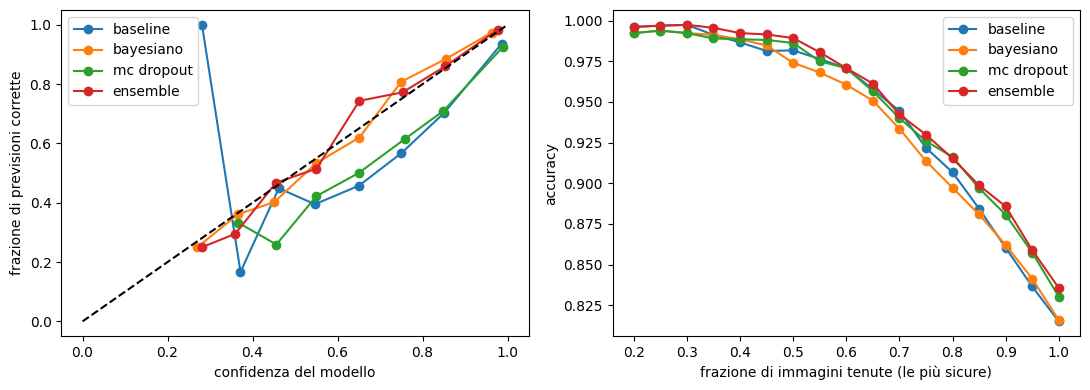

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, p in models_te:
    conf, pred = p.max(1)
    correct = (pred == yte).float()

    xs, ys = [], []
    for i in range(10):
        m = (conf > i / 10) & (conf <= (i + 1) / 10)
        if m.sum() > 0:
            xs.append(conf[m].mean().item())
            ys.append(correct[m].mean().item())
    axes[0].plot(xs, ys, "o-", label=name)

    c = correct[entropy_of(p).argsort()]
    kept = [k / 100 for k in range(20, 101, 5)]
    axes[1].plot(kept, [c[:int(len(c) * k)].mean().item() for k in kept], "o-", label=name)

axes[0].plot([0, 1], [0, 1], "k--")
axes[0].set_xlabel("confidenza del modello")
axes[0].set_ylabel("frazione di previsioni corrette")
axes[0].legend()
axes[1].set_xlabel("frazione di immagini tenute (le più sicure)")
axes[1].set_ylabel("accuracy")
axes[1].legend()
plt.tight_layout()
plt.show()